# Imports

In [1]:
import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
from tqdm import tqdm
import subprocess

import os, sys, glob
sys.path.append("D:\\DATA\\ActivePIC")
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import importlib

# Scan taper properties

Cases A-D: Single taper from small to large

In [2]:
# Define directories and files to work with
working_dir = r"D:\DATA\ActivePIC\Taper"
filename_root = "Taper"
prefix_root = f"{filename_root}_scan_TaperStart_TaperEnd_TaperLength_Wav"
save_dir = os.path.join(working_dir, prefix_root)
CAD_path = os.path.join(working_dir, f"{filename_root}.ind")
os.makedirs(save_dir, exist_ok=True)

# Load the runs, keeping only cases A-D (the case letter is whatever precedes the ':')
df = pd.read_csv(r"D:\DATA\ActivePIC\Taper\taper_runs_for_Anusha.csv")
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
df = df[case_letter.isin(["A", "B", "C", "D"])]
print(f"{len(df)} runs in cases A-D")

# Simulation settings shared by every run
Grid_size, Grid_edge, Step_z = 0.05, 0.1, 0.5

# Conduct scan
for idx, row in tqdm(df.iterrows(), total=len(df), desc="Taper runs", position=0, leave=False):
    Taper_start, Taper_end = row["w_start_um"], row["w_end_um"]
    Taper_length, wav = row["taper_length_um"], row["wavelength_nm"] / 1000

    prefix = (f"{filename_root}_scan"
              f"_TaperStart{rlib.param_str(Taper_start)}"
              f"_TaperEnd{rlib.param_str(Taper_end)}"
              f"_TaperLength{rlib.param_str(Taper_length)}"
              f"_Wav{rlib.param_str(wav)}")

    rlib.run_sim(
        CAD_path,
        prefix=os.path.join(save_dir, prefix),
        symbols={
            "free_space_wavelength": wav,
            "Taper_start": Taper_start,
            "Taper_end": Taper_end,
            "Taper_length": Taper_length,
            "Grid_size": Grid_size,
            "Grid_edge": Grid_edge,
            "Step_z": Step_z,
            "Injection_filename": rlib.mode_field(wav, Taper_start)[0],
            "Output_filename": rlib.mode_field(wav, Taper_end)[0],
        },
    )   # keeps only .mon, .json and .dat by default

69 runs in cases A-D


Taper runs:   0%|          | 0/69 [00:00<?, ?it/s]

Case A: Single taper from small to large, monitoring second even mode


λ = 1.45 μm, width = 6.7 μm: 10 modes, n_clad = 1.44519, 8 guided (n_eff > n_clad)
 number file    neff  neff-nclad pol  x_lobes  y_lobes  parity_x  parity_y  guided
      0  m00 1.46455     0.01936  Ex        1        1   1.00000       1.0    True
      1  m01 1.46444     0.01925  Ey        1        1   1.00000       1.0    True
      2  m02 1.45712     0.01193  Ex        2        1  -1.00000       1.0    True
      3  m03 1.45710     0.01190  Ey        2        1  -1.00000       1.0    True
      4  m04 1.44749     0.00229  Ex        1        2   1.00000      -1.0    True
      5  m05 1.44737     0.00218  Ey        1        2   1.00000      -1.0    True
      6  m06 1.44648     0.00128  Ex        3        1   1.00000       1.0    True
      7  m07 1.44647     0.00128  Ey        3        1   1.00000       1.0    True
      8  m08 1.44504    -0.00016  Ey        1        1   1.00000       1.0   False
      9  m09 1.44503    -0.00017  Ex        5        1   0.99999       1.0   False
  -

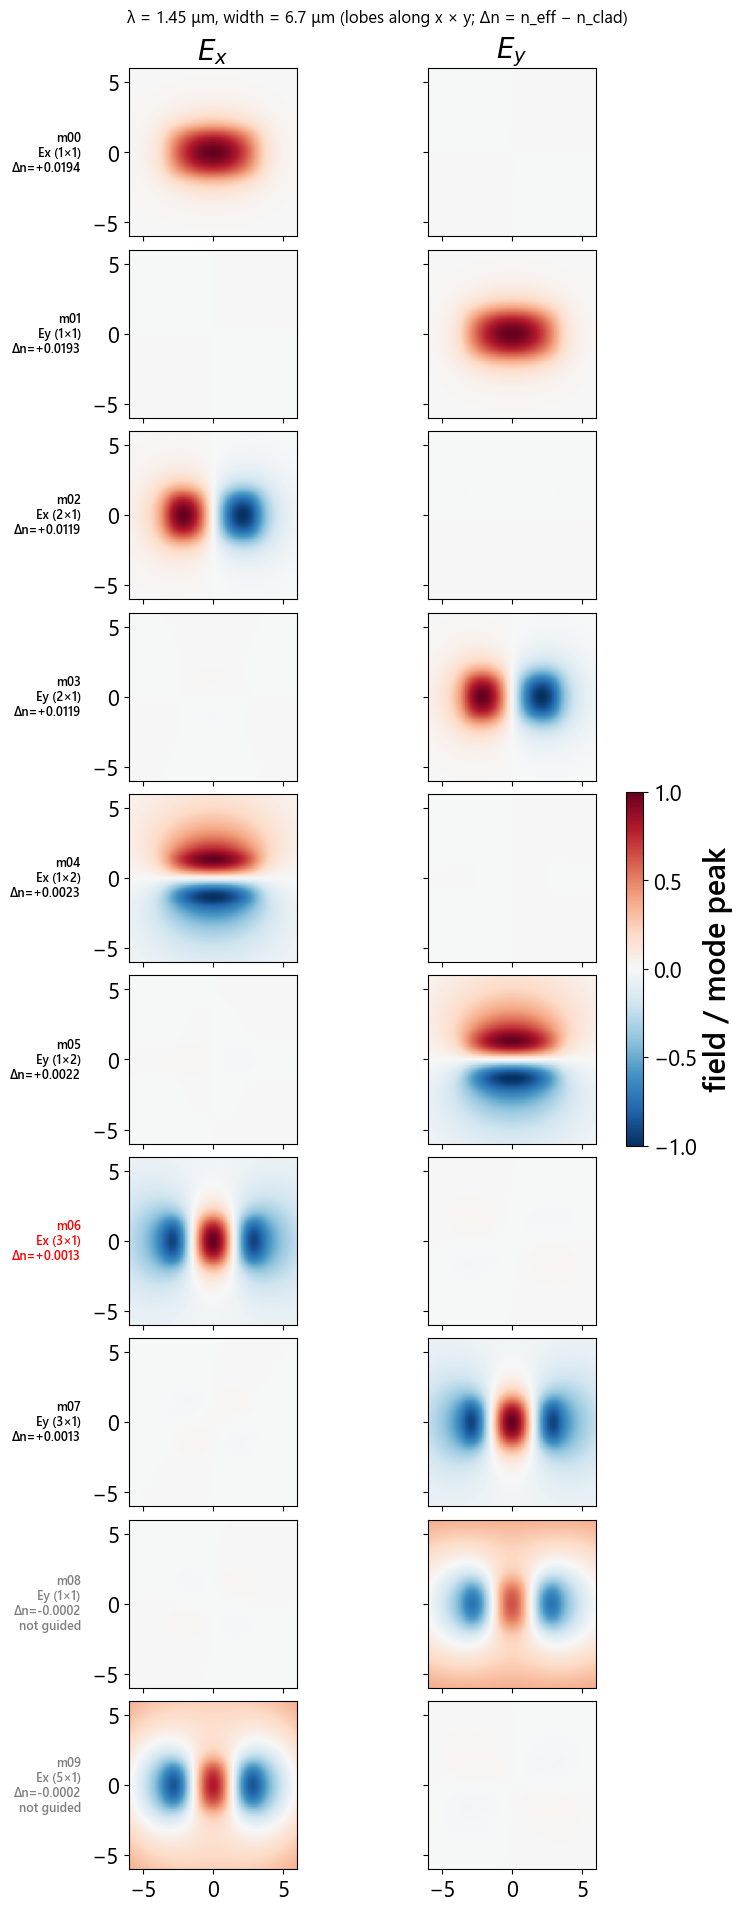


λ = 1.55 μm, width = 6.7 μm: 10 modes, n_clad = 1.44401, 6 guided (n_eff > n_clad)
 number file    neff  neff-nclad pol  x_lobes  y_lobes  parity_x  parity_y  guided
      0  m00 1.46245     0.01843  Ex        1        1       1.0       1.0    True
      1  m01 1.46233     0.01831  Ey        1        1       1.0       1.0    True
      2  m02 1.45429     0.01028  Ex        2        1      -1.0       1.0    True
      3  m03 1.45427     0.01025  Ey        2        1      -1.0       1.0    True
      4  m04 1.44487     0.00085  Ex        1        2       1.0      -1.0    True
      5  m05 1.44479     0.00078  Ey        1        2       1.0      -1.0    True
      6  m06 1.44398    -0.00003  Ex        3        1       1.0       1.0   False
      7  m07 1.44396    -0.00005  Ey        3        1       1.0       1.0   False
      8  m08 1.44382    -0.00019  Ex        2        1      -1.0       1.0   False
      9  m09 1.44380    -0.00021  Ey        1        4       1.0      -1.0   False
  -

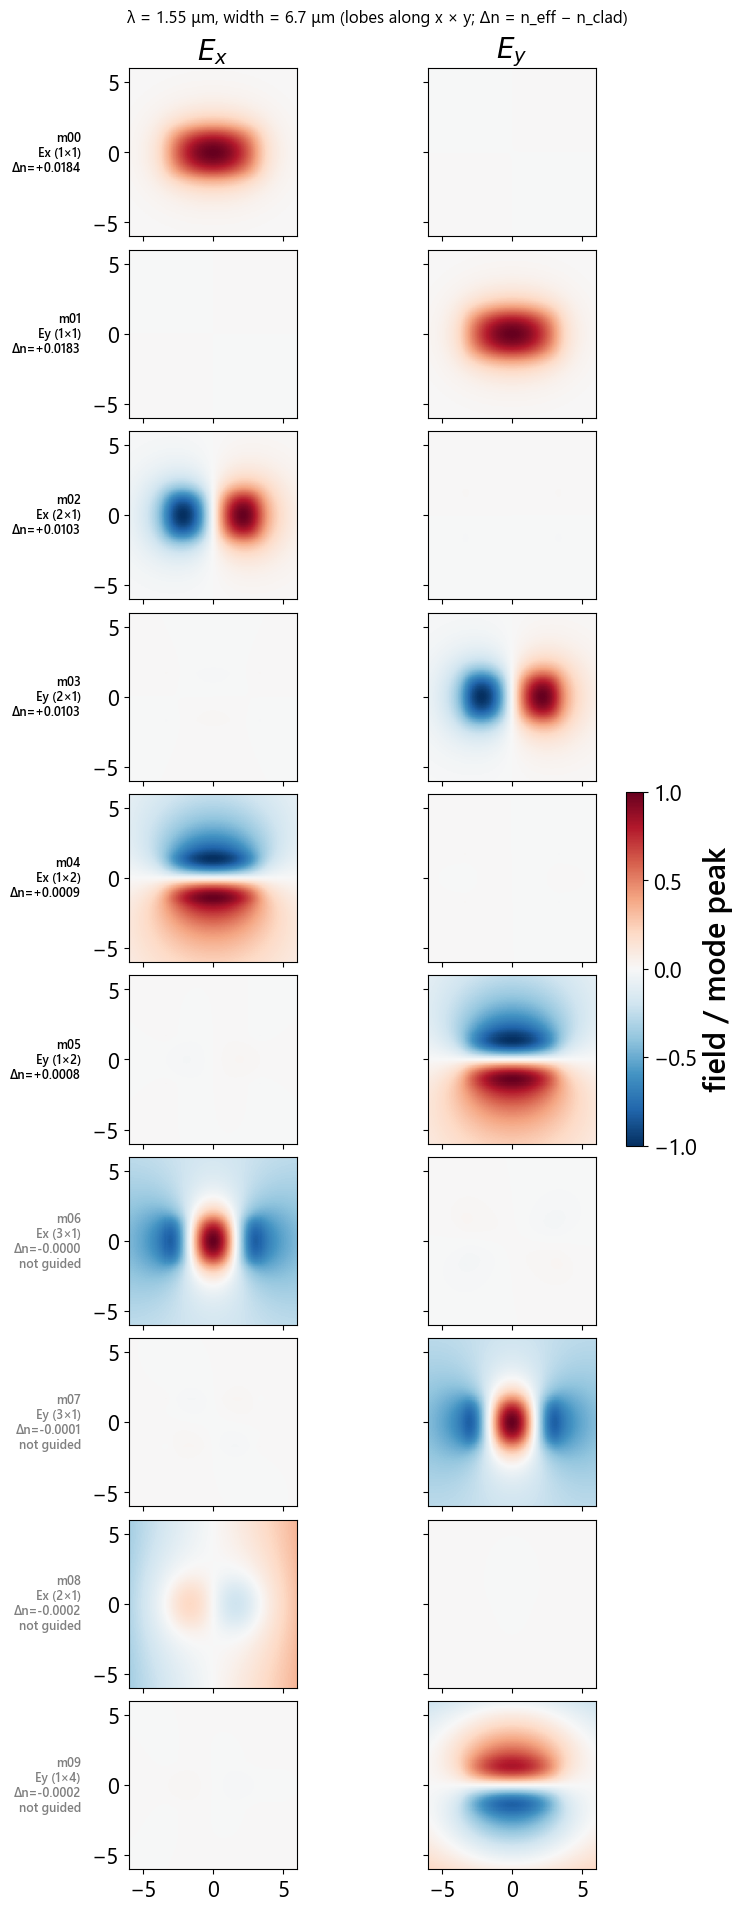


λ = 1.65 μm, width = 6.7 μm: 10 modes, n_clad = 1.44279, 4 guided (n_eff > n_clad)
 number file    neff  neff-nclad pol  x_lobes  y_lobes  parity_x  parity_y  guided
      0  m00 1.46030     0.01751  Ex        1        1       1.0       1.0    True
      1  m01 1.46017     0.01738  Ey        1        1       1.0       1.0    True
      2  m02 1.45145     0.00866  Ex        2        1      -1.0       1.0    True
      3  m03 1.45143     0.00864  Ey        2        1      -1.0       1.0    True
      4  m04 1.44274    -0.00006  Ey        1        2       1.0      -1.0   False
      5  m05 1.44271    -0.00008  Ex        1        2       1.0      -1.0   False
      6  m06 1.44264    -0.00015  Ex        3        1       1.0       1.0   False
      7  m07 1.44264    -0.00015  Ey        1        3       1.0       1.0   False
      8  m08 1.44257    -0.00022  Ex        2        1      -1.0       1.0   False
      9  m09 1.44241    -0.00038  Ey        1        2       1.0      -1.0   False
  -

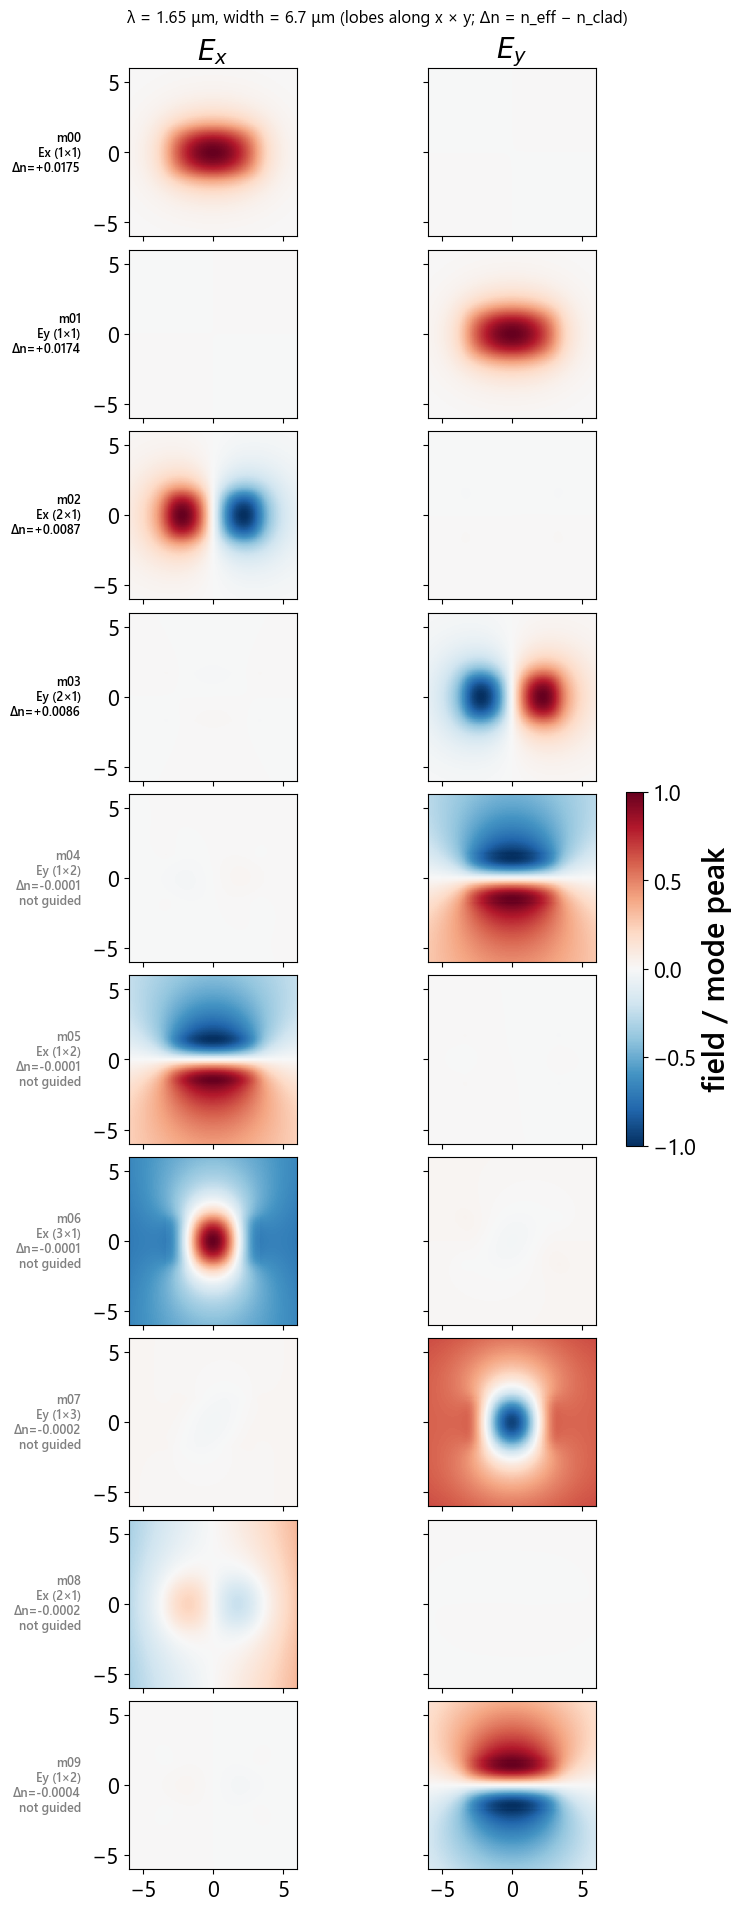


2nd even mode per wavelength: {1.45: 'm06'}


In [3]:
mode_dir = rlib.MODE_LIB_DIR
ind_file = r"D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide.ind"   # gives the cladding (background) material
width = 6.7
wavs = [1.45, 1.55, 1.65]
zoom = 6.0              # half-window in μm for the plots; None = full domain
normalize_each = False  # False: Ex and Ey share the mode's peak (the cross-component looks faint);
                        # True: each panel is scaled to its own peak (shows the cross-component's shape)

found = {}
for wav in wavs:
    stem = os.path.join(mode_dir, f"StraightWaveguide_Wav{rlib.param_str(wav)}_Width{rlib.param_str(width)}")
    n_cl = rlib.n_clad(wav, ind_file)
    df = rlib.classify_modes(stem, threshold=0.8).sort_values("neff", ascending=False)
    df.insert(1, "file", ["m" + f"{k:02d}" for k in df.number])     # extension of the mode files, e.g. m05
    df.insert(3, "neff-nclad", df.neff - n_cl)
    df["guided"] = df.neff > n_cl                                   # a guided mode has n_eff above the cladding index
    print(f"\nλ = {wav} μm, width = {width} μm: {len(df)} modes, n_clad = {n_cl:.5f}, "
          f"{df.guided.sum()} guided (n_eff > n_clad)")
    print(df.round(5).to_string(index=False))

    # 2nd even mode: guided, Ex-dominant, 3 lobes along x, 1 along y, even under x -> -x
    target = df[df.guided & (df.pol == "Ex") & (df.x_lobes == 3) & (df.y_lobes == 1) & (df.parity_x.fillna(1) > 0)]
    if len(target):
        found[wav] = int(target.number.iloc[0])
        print(f"  -> 2nd even mode: m{found[wav]:02d}, n_eff = {target.neff.iloc[0]:.5f} "
              f"(n_eff - n_clad = {target['neff-nclad'].iloc[0]:+.5f})")
    elif (~df.guided).any():
        print(f"  -> NOT FOUND, and the list already reaches non-guided modes: not guided at this width and wavelength")
    else:
        print(f"  -> NOT FOUND, and all {len(df)} modes are guided (n_eff down to {df.neff.min():.5f}): "
              f"output more modes")

    # Check by eye: Ex (left) and Ey (right) of every mode, chosen mode in red, non-guided modes in gray
    fig, axes = plt.subplots(len(df), 2, figsize=(7.5, 1.9 * len(df)), squeeze=False,
                             sharex=True, sharey=True, constrained_layout=True)
    for i, row in enumerate(df.itertuples()):
        fx = rlib.read_mode(f"{stem}_ex.m{row.number:02d}")
        fy = rlib.read_mode(f"{stem}_ey.m{row.number:02d}")
        sx, sy = fx.signed_field(), fy.signed_field()
        peak = max(np.abs(sx).max(), np.abs(sy).max())
        for j, (f, s) in enumerate(((fx, sx), (fy, sy))):
            scale = np.abs(s).max() if normalize_each else peak
            im = axes[i, j].pcolormesh(f.x, f.y, s / scale, cmap="RdBu_r", vmin=-1, vmax=1, shading="auto")
            axes[i, j].set_aspect("equal")
        axes[i, 0].set_ylabel(f"{row.file}\n{row.pol} ({row.x_lobes}×{row.y_lobes})\nΔn={row.neff - n_cl:+.4f}"
                              + ("" if row.guided else "\nnot guided"), rotation=0,
                              ha="right", va="center", fontsize=9, labelpad=8,
                              color="red" if found.get(wav) == row.number else ("gray" if not row.guided else "black"))
    axes[0, 0].set_title("$E_x$")
    axes[0, 1].set_title("$E_y$")
    if zoom:
        axes[0, 0].set_xlim(-zoom, zoom)
        axes[0, 0].set_ylim(-zoom, zoom)
    fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.03, shrink=0.4,
                 label="field / own peak" if normalize_each else "field / mode peak")
    fig.suptitle(f"λ = {wav} μm, width = {width} μm (lobes along x × y; Δn = n_eff − n_clad)")
    plt.show()

print("\n2nd even mode per wavelength:", {w: f"m{k:02d}" for w, k in found.items()})

In [7]:
# Define directories and files to work with
working_dir = r"D:\DATA\ActivePIC\Taper"
filename_root = "Taper"
prefix_root = f"{filename_root}_scan_TaperStart_TaperEnd_TaperLength_Wav"
save_dir = os.path.join(working_dir, prefix_root)
CAD_path = os.path.join(working_dir, f"{filename_root}.ind")
os.makedirs(save_dir, exist_ok=True)

# Load the runs, keeping only case A (the case letter is whatever precedes the ':')
df = pd.read_csv(r"D:\DATA\ActivePIC\Taper\taper_runs_for_Anusha.csv")
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
df = df[case_letter.isin(["A"])]
print(f"{len(df)} runs in case A")

# Simulation settings shared by every run
Grid_size, Grid_edge, Step_z = 0.05, 0.1, 0.5

# Conduct scan
for idx, row in tqdm(df.iterrows(), total=len(df), desc="Taper runs", position=0, leave=False):
    Taper_start, Taper_end = row["w_start_um"], row["w_end_um"]
    Taper_length, wav = row["taper_length_um"], row["wavelength_nm"] / 1000

    prefix = (f"{filename_root}_scan"
              f"_TaperStart{rlib.param_str(Taper_start)}"
              f"_TaperEnd{rlib.param_str(Taper_end)}"
              f"_TaperLength{rlib.param_str(Taper_length)}"
              f"_Wav{rlib.param_str(wav)}")

    rlib.run_sim(
        CAD_path,
        prefix=os.path.join(save_dir, prefix),
        symbols={
            "free_space_wavelength": wav,
            "Taper_start": Taper_start,
            "Taper_end": Taper_end,
            "Taper_length": Taper_length,
            "Grid_size": Grid_size,
            "Grid_edge": Grid_edge,
            "Step_z": Step_z,
            "Injection_filename": rlib.mode_field(wav, Taper_start)[0],
            "Output_filename": rlib.mode_field(wav, Taper_end)[0],
            "Output_2_filename":rlib.mode_field(1.45, 6.7)[0].replace('m00', 'm06')
        },
    )   # keeps only .mon, .json and .dat by default

12 runs in case A


Case E: ripple taper, i.e. small --> large --> small

In [ ]:
# Define directories and files to work with
working_dir = r"D:\DATA\ActivePIC\Taper"
filename_root = "Taper_ripple"
prefix_root = f"{filename_root}_scan_TaperStart_TaperEnd_TaperLength_Wav"
save_dir = os.path.join(working_dir, prefix_root)
CAD_path = os.path.join(working_dir, f"{filename_root}.ind")
os.makedirs(save_dir, exist_ok=True)

# Load the runs, keeping only cases A-D (the case letter is whatever precedes the ':')
df = pd.read_csv(r"D:\DATA\ActivePIC\Taper\taper_runs_for_Anusha.csv")
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
df = df[case_letter.isin(["E"])]
print(f"{len(df)} runs in case E")

# Simulation settings shared by every run
Grid_size, Grid_edge, Step_z = 0.05, 0.1, 0.5

# Conduct scan
for idx, row in tqdm(df.iterrows(), total=len(df), desc="Taper runs", position=0, leave=False):
    Taper_start, Taper_end = row["w_start_um"], row["w_end_um"]
    Taper_length, wav = row["taper_length_um"], row["wavelength_nm"] / 1000

    prefix = (f"{filename_root}_scan"
              f"_TaperStart{rlib.param_str(Taper_start)}"
              f"_TaperEnd{rlib.param_str(Taper_end)}"
              f"_TaperLength{rlib.param_str(Taper_length)}"
              f"_Wav{rlib.param_str(wav)}")

    rlib.run_sim(
        CAD_path,
        prefix=os.path.join(save_dir, prefix),
        symbols={
            "free_space_wavelength": wav,
            "Taper_start": Taper_start,
            "Taper_end": Taper_end,
            "Taper_length": Taper_length,
            "Grid_size": Grid_size,
            "Grid_edge": Grid_edge,
            "Step_z": Step_z,
            "Injection_filename": rlib.mode_field(wav, Taper_start)[0],
            "Output_filename": rlib.mode_field(wav, Taper_start)[0],
        },
    )   # keeps only .mon, .json and .dat by default

Case F: convergence test for 2.5 μm --> 6.7 μm with dz = 0.25 μm, grid = 0.025 μm

In [3]:
# Define directories and files to work with
working_dir = r"D:\DATA\ActivePIC\Taper"
filename_root = "Taper"
prefix_root = f"{filename_root}_convergenceTest"
save_dir = os.path.join(working_dir, prefix_root)
CAD_path = os.path.join(working_dir, f"{filename_root}.ind")
os.makedirs(save_dir, exist_ok=True)

# Load the runs, keeping only case F (the case letter is whatever precedes the ':')
df = pd.read_csv(r"D:\DATA\ActivePIC\Taper\taper_runs_for_Anusha.csv")
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
df = df[case_letter.isin(["F"])]
print(f"{len(df)} runs in case F")

# Simulation settings shared by every run
Grid_size, Grid_edge, Step_z = 0.025, 0.1, 0.25

# Conduct scan
for idx, row in tqdm(df.iterrows(), total=len(df), desc="Taper runs", position=0, leave=False):
    Taper_start, Taper_end = row["w_start_um"], row["w_end_um"]
    Taper_length, wav = row["taper_length_um"], row["wavelength_nm"] / 1000

    prefix = (f"{filename_root}_scan"
              f"_TaperStart{rlib.param_str(Taper_start)}"
              f"_TaperEnd{rlib.param_str(Taper_end)}"
              f"_TaperLength{rlib.param_str(Taper_length)}"
              f"_Wav{rlib.param_str(wav)}")

    rlib.run_sim(
        CAD_path,
        prefix=os.path.join(save_dir, prefix),
        symbols={
            "free_space_wavelength": wav,
            "Taper_start": Taper_start,
            "Taper_end": Taper_end,
            "Taper_length": Taper_length,
            "Grid_size": Grid_size,
            "Grid_edge": Grid_edge,
            "Step_z": Step_z,
            "Injection_filename": rlib.mode_field(wav, Taper_start)[0],
            "Output_filename": rlib.mode_field(wav, Taper_end)[0],
        },
    )   # keeps only .mon, .json and .dat by default

1 runs in case F


# Fill in taper table

Fill in T_fund_dB column: cases A-D

In [8]:
working_dir = r"D:\DATA\ActivePIC\Taper"
filename_root = "Taper"
prefix_root = f"{filename_root}_scan_TaperStart_TaperEnd_TaperLength_Wav"
save_dir = os.path.join(working_dir, prefix_root)
csv_in = os.path.join(working_dir, "taper_runs_for_Anusha.csv")
csv_out = os.path.join(working_dir, "taper_runs_for_Anusha_filled.csv")

df = pd.read_csv(csv_in)
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
in_cases = case_letter.isin(["A", "B", "C", "D"])

missing, zero_power = [], []
for idx in df.index[in_cases]:
    row = df.loc[idx]
    prefix = (f"{filename_root}_scan"
              f"_TaperStart{rlib.param_str(row['w_start_um'])}"
              f"_TaperEnd{rlib.param_str(row['w_end_um'])}"
              f"_TaperLength{rlib.param_str(row['taper_length_um'])}"
              f"_Wav{rlib.param_str(row['wavelength_nm'] / 1000)}")
    path = os.path.join(save_dir, prefix + ".mon")
    if not os.path.exists(path):
        missing.append(prefix)
        continue

    power = rlib.read_monitor(path).values[-1, 0]       # last row, first monitor (2nd column of the file)
    if power > 0:
        df.loc[idx, "T_fund_dB"] = 10 * np.log10(power)
    else:
        zero_power.append(prefix)

df.to_csv(csv_out, index=False)
print(f"Filled {df.loc[in_cases, 'T_fund_dB'].notna().sum()} of {in_cases.sum()} rows in cases A-D -> {csv_out}")
if missing:
    print(f"{len(missing)} missing .mon files (left blank):", *missing, sep="\n  ")
if zero_power:
    print(f"{len(zero_power)} runs with zero power (left blank):", *zero_power, sep="\n  ")

Filled 69 of 69 rows in cases A-D -> D:\DATA\ActivePIC\Taper\taper_runs_for_Anusha_filled.csv


Fill in P_2nd_mode_or_phase_deg column: case A

In [18]:
working_dir = r"D:\DATA\ActivePIC\Taper"
filename_root = "Taper"
prefix_root = f"{filename_root}_scan_TaperStart_TaperEnd_TaperLength_Wav"
save_dir = os.path.join(working_dir, prefix_root)
csv_in = os.path.join(working_dir, "taper_runs_for_Anusha.csv")
csv_out = os.path.join(working_dir, "taper_runs_for_Anusha_filled.csv")
second_mode_in_dB = True    # False: store the 2nd-mode power as the raw monitor value; True: store 10*log10 of it

df = pd.read_csv(csv_in)
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
in_cases = case_letter.isin(["A", "B", "C", "D"])

missing, zero_power, no_second = [], [], []
for idx in df.index[in_cases]:
    row = df.loc[idx]
    prefix = (f"{filename_root}_scan"
              f"_TaperStart{rlib.param_str(row['w_start_um'])}"
              f"_TaperEnd{rlib.param_str(row['w_end_um'])}"
              f"_TaperLength{rlib.param_str(row['taper_length_um'])}"
              f"_Wav{rlib.param_str(row['wavelength_nm'] / 1000)}")
    path = os.path.join(save_dir, prefix + ".mon")
    if not os.path.exists(path):
        missing.append(prefix)
        continue

    mon = rlib.read_monitor(path)
    power = mon.values[-1, 0]       # last row, first monitor (2nd column of the file)
    if power > 0:
        df.loc[idx, "T_fund_dB"] = 10 * np.log10(power)
    else:
        zero_power.append(prefix)

    # Case A only: transmission in the second even mode (last row, third monitor)
    if case_letter[idx] == "A":
        if mon.values.shape[1] <= 2:
            no_second.append(prefix)
        else:
            p2 = mon.values[-1, 2]
            if second_mode_in_dB:
                p2 = 10 * np.log10(p2) if p2 > 0 else np.nan
            df.loc[idx, "P_2nd_mode_or_phase_deg"] = p2

df.to_csv(csv_out, index=False)
print(f"Filled {df.loc[in_cases, 'T_fund_dB'].notna().sum()} of {in_cases.sum()} rows in cases A-D -> {csv_out}")
is_A = case_letter == "A"
print(f"Second even mode filled for {df.loc[is_A, 'P_2nd_mode_or_phase_deg'].notna().sum()} of {is_A.sum()} case A rows")
if missing:
    print(f"{len(missing)} missing .mon files (left blank):", *missing, sep="\n  ")
if zero_power:
    print(f"{len(zero_power)} runs with zero power (left blank):", *zero_power, sep="\n  ")
if no_second:
    print(f"{len(no_second)} case A files with fewer than 3 monitors (2nd-mode value left blank):", *no_second, sep="\n  ")

Filled 69 of 69 rows in cases A-D -> D:\DATA\ActivePIC\Taper\taper_runs_for_Anusha_filled.csv
Second even mode filled for 12 of 12 case A rows


Fill in T_fund_dB column: case E

In [13]:
working_dir = r"D:\DATA\ActivePIC\Taper"
csv_filled = os.path.join(working_dir, "taper_runs_for_Anusha_filled.csv")
save_dir = os.path.join(working_dir, "Taper_ripple_scan_TaperStart_TaperEnd_TaperLength_Wav")
monitor_index = 0    # column of .values to use: 0 = first monitor (2nd column of the file)

df = pd.read_csv(csv_filled)
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
rows = df.index[case_letter == "E"]

missing, zero_power = [], []
for idx in rows:
    row = df.loc[idx]
    tag = (f"TaperStart{rlib.param_str(row['w_start_um'])}"
           f"_TaperEnd{rlib.param_str(row['w_end_um'])}"
           f"_TaperLength{rlib.param_str(row['taper_length_um'])}"
           f"_Wav{rlib.param_str(row['wavelength_nm'] / 1000)}")
    matches = glob.glob(os.path.join(save_dir, f"*{tag}.mon"))
    print(matches)
    if len(matches) != 1:
        missing.append(f"{tag} ({len(matches)} matches)")
        continue

    mon = rlib.read_monitor(matches[0])
    power = mon.values[-1, 0]       # last row, first monitor (2nd column of the file)
    if power > 0:
        df.loc[idx, "T_fund_dB"] = 10 * np.log10(power)
    else:
        zero_power.append(prefix)

df.to_csv(csv_filled, index=False)
print(f"Case E: filled {df.loc[rows, 'T_fund_dB'].notna().sum()} of {len(rows)} rows -> {csv_filled}")
if missing:
    print(f"{len(missing)} missing or ambiguous .mon files (left blank):", *missing, sep="\n  ")
if zero_power:
    print(f"{len(zero_power)} runs with zero power (left blank):", *zero_power, sep="\n  ")

['D:\\DATA\\ActivePIC\\Taper\\Taper_ripple_scan_TaperStart_TaperEnd_TaperLength_Wav\\Taper_ripple_scan_TaperStart2p500_TaperEnd6p700_TaperLength160p000_Wav1p450.mon']
['D:\\DATA\\ActivePIC\\Taper\\Taper_ripple_scan_TaperStart_TaperEnd_TaperLength_Wav\\Taper_ripple_scan_TaperStart2p500_TaperEnd6p700_TaperLength160p000_Wav1p460.mon']
['D:\\DATA\\ActivePIC\\Taper\\Taper_ripple_scan_TaperStart_TaperEnd_TaperLength_Wav\\Taper_ripple_scan_TaperStart2p500_TaperEnd6p700_TaperLength160p000_Wav1p470.mon']
['D:\\DATA\\ActivePIC\\Taper\\Taper_ripple_scan_TaperStart_TaperEnd_TaperLength_Wav\\Taper_ripple_scan_TaperStart2p500_TaperEnd6p700_TaperLength160p000_Wav1p480.mon']
['D:\\DATA\\ActivePIC\\Taper\\Taper_ripple_scan_TaperStart_TaperEnd_TaperLength_Wav\\Taper_ripple_scan_TaperStart2p500_TaperEnd6p700_TaperLength160p000_Wav1p490.mon']
['D:\\DATA\\ActivePIC\\Taper\\Taper_ripple_scan_TaperStart_TaperEnd_TaperLength_Wav\\Taper_ripple_scan_TaperStart2p500_TaperEnd6p700_TaperLength160p000_Wav1p500.mon'

Fill in P_2nd_mode_or_phase_deg column: case E

In [19]:
working_dir = r"D:\DATA\ActivePIC\Taper"
csv_filled = os.path.join(working_dir, "taper_runs_for_Anusha_filled.csv")   # already has cases A-D
save_dir = os.path.join(working_dir, "Taper_ripple_scan_TaperStart_TaperEnd_TaperLength_Wav")
monitor_index = 0           # column of .values with the power (0 = first monitor, the 2nd column of the file)
normalize_to_start = False  # True: divide the last power by the first sample; False: use the last value as is

df = pd.read_csv(csv_filled)
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
rows = df.index[case_letter == "E"]

missing, zero_power, no_phase = [], [], []
for idx in rows:
    row = df.loc[idx]
    tag = (f"TaperStart{rlib.param_str(row['w_start_um'])}"
           f"_TaperEnd{rlib.param_str(row['w_end_um'])}"
           f"_TaperLength{rlib.param_str(row['taper_length_um'])}"
           f"_Wav{rlib.param_str(row['wavelength_nm'] / 1000)}")
    matches = glob.glob(os.path.join(save_dir, f"*{tag}.mon"))
    if len(matches) != 1:
        missing.append(f"{tag} ({len(matches)} matches)")
        continue

    mon = rlib.read_monitor(matches[0])
    p_out = mon.values[-1, monitor_index]
    p_in = mon.values[0, monitor_index] if normalize_to_start else 1.0
    if p_in > 0 and p_out > 0:
        df.loc[idx, "T_fund_dB"] = 10 * np.log10(p_out / p_in)
    else:
        zero_power.append(tag)

    # Phase, as the column name says: last row, second monitor (degrees, wrapped by the monitor)
    if mon.values.shape[1] > 1:
        df.loc[idx, "P_2nd_mode_or_phase_deg"] = mon.values[-1, 1]
    else:
        no_phase.append(tag)

df.to_csv(csv_filled, index=False)
print(f"Case E: filled {df.loc[rows, 'T_fund_dB'].notna().sum()} of {len(rows)} transmissions and "
      f"{df.loc[rows, 'P_2nd_mode_or_phase_deg'].notna().sum()} phases -> {csv_filled}")
if missing:
    print(f"{len(missing)} missing or ambiguous .mon files (left blank):", *missing, sep="\n  ")
if zero_power:
    print(f"{len(zero_power)} runs with zero power (transmission left blank):", *zero_power, sep="\n  ")
if no_phase:
    print(f"{len(no_phase)} files with only one monitor (phase left blank):", *no_phase, sep="\n  ")

Case E: filled 21 of 21 transmissions and 21 phases -> D:\DATA\ActivePIC\Taper\taper_runs_for_Anusha_filled.csv


Fill in T_fund_dB column: case F

In [21]:
working_dir = r"D:\DATA\ActivePIC\Taper"
csv_filled = os.path.join(working_dir, "taper_runs_for_Anusha_filled.csv")   # already has cases A-E
save_dir = os.path.join(working_dir, "Taper_convergenceTest")
monitor_index = 0    # column of .values to use: 0 = first monitor (2nd column of the file)

df = pd.read_csv(csv_filled)
case_letter = df["case"].str.split(":").str[0].str.strip().str.upper()
rows = df.index[case_letter == "F"]

missing, zero_power = [], []
for idx in rows:
    row = df.loc[idx]
    tag = (f"TaperStart{rlib.param_str(row['w_start_um'])}"
           f"_TaperEnd{rlib.param_str(row['w_end_um'])}"
           f"_TaperLength{rlib.param_str(row['taper_length_um'])}"
           f"_Wav{rlib.param_str(row['wavelength_nm'] / 1000)}")
    matches = glob.glob(os.path.join(save_dir, f"*{tag}.mon"))
    if len(matches) != 1:
        missing.append(f"{tag} ({len(matches)} matches)")
        continue

    power = rlib.read_monitor(matches[0]).values[-1, monitor_index]
    if power > 0:
        df.loc[idx, "T_fund_dB"] = 10 * np.log10(power)
    else:
        zero_power.append(tag)

df.to_csv(csv_filled, index=False)
print(f"Case F: filled {df.loc[rows, 'T_fund_dB'].notna().sum()} of {len(rows)} rows -> {csv_filled}")
if missing:
    print(f"{len(missing)} missing or ambiguous .mon files (left blank):", *missing, sep="\n  ")
    if os.path.isdir(save_dir):
        print("Files in the folder, for comparison:", *sorted(os.listdir(save_dir))[:5], sep="\n  ")
if zero_power:
    print(f"{len(zero_power)} runs with zero power (left blank):", *zero_power, sep="\n  ")

Case F: filled 1 of 1 rows -> D:\DATA\ActivePIC\Taper\taper_runs_for_Anusha_filled.csv


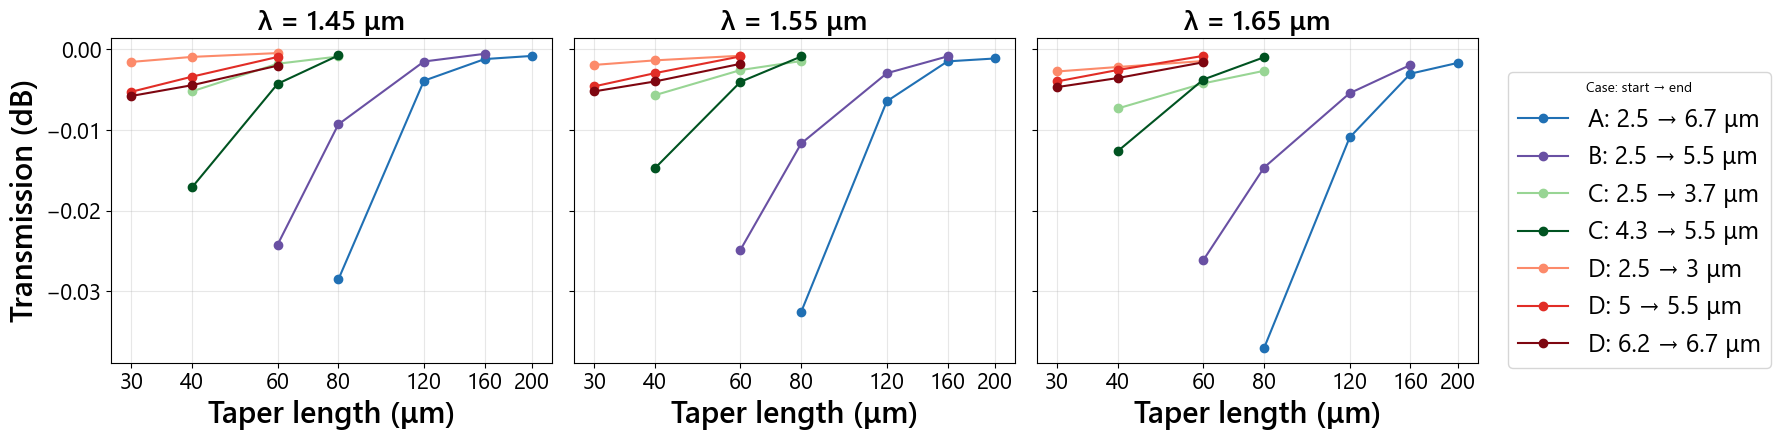

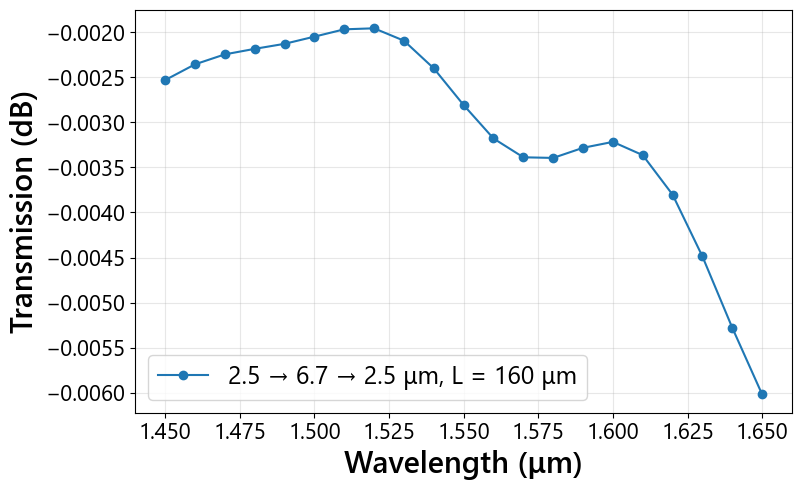

Convergence check (case F vs the same run in cases A-E), tolerance 0.01 dB
  row 90: 2.5 -> 6.7 um, L = 120 um, 1450 nm: -0.0037 dB vs -0.0039 dB (case A), diff = +0.0001 dB -> OK
  max |diff| = 0.0001 dB over 1 comparisons: converged to within 0.01 dB


In [25]:
working_dir = r"D:\DATA\ActivePIC\Taper"
csv_filled = os.path.join(working_dir, "taper_runs_for_Anusha_filled.csv")
tol_dB = 0.01    # convergence: max |T(case F) - T(baseline run)| allowed

df_all = pd.read_csv(csv_filled)
df_all["case_letter"] = df_all["case"].str.split(":").str[0].str.strip().str.upper()
df = df_all.dropna(subset=["T_fund_dB"])

# ---- Taper cases A-D: transmission vs taper length, one line per (start -> end) taper, one panel per wavelength
tap = df[df.case_letter.isin(["A", "B", "C", "D"])]
pairs = list(tap[["case_letter", "w_start_um", "w_end_um"]].drop_duplicates()
             .sort_values(["case_letter", "w_start_um", "w_end_um"]).itertuples(index=False))
wavs = np.sort(tap.wavelength_nm.unique())

# One color per case, with a different shade for each taper within the case (light -> dark)
case_cmaps = {"A": plt.cm.Blues, "B": plt.cm.Purples, "C": plt.cm.Greens, "D": plt.cm.Reds}
shades = {}
for case, cmap in case_cmaps.items():
    n = sum(p[0] == case for p in pairs)
    shades[case] = iter(np.linspace(0.4, 0.95, n) if n > 1 else [0.75])

fig, axes = plt.subplots(1, len(wavs), figsize=(5 * len(wavs), 4.5), sharey=True, sharex=True, squeeze=False)
for case, s, e in pairs:
    color = case_cmaps[case](next(shades[case]))
    taper = tap[(tap.case_letter == case) & np.isclose(tap.w_start_um, s) & np.isclose(tap.w_end_um, e)]
    for j, w in enumerate(wavs):
        t = taper[taper.wavelength_nm == w].sort_values("taper_length_um")
        axes[0, j].plot(t.taper_length_um, t.T_fund_dB, marker="o", color=color,
                        label=f"{case}: {s:g} → {e:g} μm")
lengths = np.sort(tap.taper_length_um.unique())
for j, w in enumerate(wavs):
    ax = axes[0, j]
    ax.set_title(f"λ = {w / 1000:.2f} μm")
    ax.set_xscale("log")
    ax.set_xticks(lengths)
    ax.set_xticklabels([f"{L:g}" for L in lengths])
    ax.minorticks_off()
    ax.set_xlabel("Taper length (μm)")
    ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("Transmission (dB)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), title="Case: start → end")
plt.tight_layout()
plt.show()

# ---- Ripple taper, case E: transmission vs wavelength, one line per taper
rip = df[df.case_letter == "E"]
fig, ax = plt.subplots(figsize=(8, 5))
for (s, e, L), sub in rip.groupby(["w_start_um", "w_end_um", "taper_length_um"]):
    sub = sub.sort_values("wavelength_nm")
    ax.plot(sub.wavelength_nm / 1000, sub.T_fund_dB, marker="o", label=f"{s:g} → {e:g} → {s:g} μm, L = {L:g} μm")
ax.set_xlabel("Wavelength (μm)")
ax.set_ylabel("Transmission (dB)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ---- Convergence test, case F: compare against the same taper and wavelength in cases A-E
keys = ["w_start_um", "w_end_um", "taper_length_um", "wavelength_nm"]
others = df[df.case_letter != "F"]
diffs = []
print(f"Convergence check (case F vs the same run in cases A-E), tolerance {tol_dB} dB")
for idx, r in df_all[df_all.case_letter == "F"].iterrows():
    desc = f"{r.w_start_um:g} -> {r.w_end_um:g} um, L = {r.taper_length_um:g} um, {r.wavelength_nm:g} nm"
    if pd.isna(r.T_fund_dB):
        print(f"  row {idx}: {desc}: T not filled in yet")
        continue
    match = others[np.all([np.isclose(others[k], r[k]) for k in keys], axis=0)]
    if match.empty:
        print(f"  row {idx}: {desc}: no matching run in cases A-E to compare with")
        continue
    ref = match.iloc[0]
    d = r.T_fund_dB - ref.T_fund_dB
    diffs.append(abs(d))
    print(f"  row {idx}: {desc}: {r.T_fund_dB:.4f} dB vs {ref.T_fund_dB:.4f} dB (case {ref.case_letter}), "
          f"diff = {d:+.4f} dB -> {'OK' if abs(d) <= tol_dB else 'NOT CONVERGED'}")
if diffs:
    print(f"  max |diff| = {max(diffs):.4f} dB over {len(diffs)} comparisons: "
          f"{'converged' if max(diffs) <= tol_dB else 'NOT converged'} to within {tol_dB} dB")
else:
    print("  no comparisons could be made")

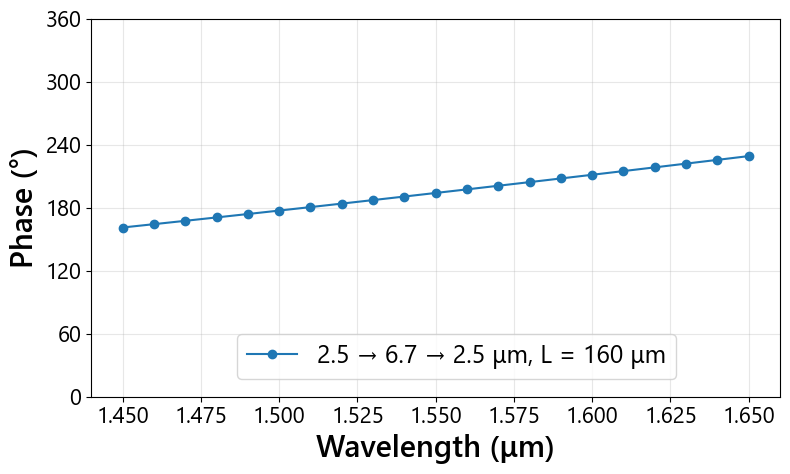

In [29]:
working_dir = r"D:\DATA\ActivePIC\Taper"
csv_filled = os.path.join(working_dir, "taper_runs_for_Anusha_filled.csv")

df = pd.read_csv(csv_filled)
df["case_letter"] = df["case"].str.split(":").str[0].str.strip().str.upper()
rip = df[(df.case_letter == "E")].dropna(subset=["P_2nd_mode_or_phase_deg"])

# Case E: phase (the P_2nd_mode_or_phase_deg column) vs wavelength, one line per taper
fig, ax = plt.subplots(figsize=(8, 5.5))
for (s, e, L), sub in rip.groupby(["w_start_um", "w_end_um", "taper_length_um"]):
    sub = sub.sort_values("wavelength_nm")
    ax.plot(sub.wavelength_nm / 1000, sub.P_2nd_mode_or_phase_deg, marker="o",
            label=f"{s:g} → {e:g} → {s:g} μm, L = {L:g} μm")
ax.set_xlabel("Wavelength (μm)")
ax.set_ylabel("Phase (°)")
ax.set_ylim(0, 360)
ax.set_yticks(range(0, 361, 60))
ax.grid(alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
# fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.legend(loc=(0.3, 0.2))
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

In [5]:
import os

import numpy as np
from tqdm import tqdm

import rsoft_lib as rlib

# Define directories and files to work with
working_dir = r"D:\DATA\ActivePIC\SingleWaveguideConvergence"
save_dir = os.path.join(working_dir, "StraightWaveguide_neff_table")
os.makedirs(save_dir, exist_ok=True)
filename_root = "StraightWaveguide"
CAD_path = os.path.join(working_dir, f"{filename_root}_higherModes.ind")

# Define parameter scan
grid_size = 0.05
grid_edge = 0.5
wav_arr = np.array([1.45, 1.55, 1.65])
# width_arr = np.hstack([2.3, 2.35, np.arange(2.4, 3.4, 0.05)])
width_arr = np.array([6.7])

# Keep the .nef table and every mode file (.m00, .m01, ... for all components); delete the rest.
# This is large: each mode file is ~7 MB and there are 6 per mode. To keep only Ex and Ey (what
# rlib.classify_modes needs), use "_ex.m[0-9][0-9]" and "_ey.m[0-9][0-9]" in place of ".m[0-9][0-9]".
keep_ext = (".mon", ".json", ".dat", ".nef", ".m[0-9][0-9]", ".m[0-9][0-9][0-9]")

for width in tqdm(width_arr, desc='Width loop', position=0, leave=False):
    for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False):
        prefix = f"{filename_root}_Wav{rlib.param_str(wav)}_Width{rlib.param_str(width)}"

        rlib.run_sim(
            CAD_path,
            prefix=os.path.join(save_dir, prefix),
            symbols={
                "free_space_wavelength": wav,
                "width": width,
                "height": 3.4,
                "Contrast": 1.02,
                "Grid_x": grid_size,
                "Grid_y": grid_size,
                "Grid_z": grid_size,
                "Grid_Edge": grid_edge,
                "PML_width": 5,
                "Volume_transverse": width + 10,
            },
            exe="femsim",
            args=["mode_method=1", "mode_set=1", "idbpm_convergence_warning=0"],
            keep_ext=keep_ext,
        )

        nef = np.atleast_2d(np.genfromtxt(os.path.join(save_dir, prefix + ".nef")))   # one row per mode: [index, n_eff]
        tqdm.write(f"W = {width:.3f}, wav = {wav:.3f}: {len(nef)} modes, n_eff of the first three: {nef[:3, 1]}")

Wavelength loop:   0%|          | 0/3 [00:00<?, ?it/s]

Wavelength loop:  33%|███▎      | 1/3 [20:14<40:28, 1214.42s/it]

W = 6.700, wav = 1.450: 10 modes, n_eff of the first three: [1.46455276 1.46444452 1.45711982]


Wavelength loop:  67%|██████▋   | 2/3 [41:40<20:56, 1256.46s/it]

W = 6.700, wav = 1.550: 10 modes, n_eff of the first three: [1.46244669 1.46232772 1.45429254]


W = 6.700, wav = 1.650: 10 modes, n_eff of the first three: [1.46030319 1.46017432 1.4514544 ]
